# Experiment B: Supervised Buzzer Detection
**Goal:** Train classifier dengan manual labels, compare dengan unsupervised

**Prerequisites:** Manual labeling di `data/labels/top30_for_review.csv` & `random20_for_review.csv`

**Model:** Random Forest (baseline)

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("Setup complete")

Setup complete


## 2. Load Labeled Data

In [ ]:
import os
if not os.path.exists("../data/labels/"):
    raise FileNotFoundError("Run notebook 04a first to generate label files")

top30 = pd.read_csv("../data/labels/batch3_top30_for_review.csv")
random20 = pd.read_csv("../data/labels/batch3_random20_for_review.csv")

labeled = pd.concat([top30, random20], ignore_index=True)

if labeled["label"].isna().all() or (labeled["label"] == "").all():
    raise ValueError("No labels found! Please add labels (0 or 1) in 'label' column")

labeled["label"] = pd.to_numeric(labeled["label"], errors="coerce")
labeled = labeled.dropna(subset=["label"])
labeled["label"] = labeled["label"].astype(int)

print(f"Loaded {len(labeled)} labeled accounts")
print(f"  Buzzer: {(labeled['label'] == 1).sum()}")
print(f"  Organic: {(labeled['label'] == 0).sum()}")
print(f"\nClass balance: {(labeled['label'] == 1).sum() / len(labeled) * 100:.1f}% buzzer")

labeled.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/labels/.batch3_random20_for_review.csv'

## 3. Load Full Features

In [ ]:
accounts = pd.read_csv("../data/features/batch3_account_features_with_scores.csv")

accounts = accounts.merge(labeled[["username", "label"]], on="username", how="left")

labeled_accounts = accounts[accounts["label"].notna()].copy()
unlabeled_accounts = accounts[accounts["label"].isna()].copy()

print(f"Total accounts: {len(accounts)}")
print(f"  Labeled: {len(labeled_accounts)}")
print(f"  Unlabeled: {len(unlabeled_accounts)}")

labeled_accounts.head()

Total accounts: 1007
  Labeled: 50
  Unlabeled: 957


,account_id,username,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,first_post,last_post,...,out_degree,pagerank,score_post_rate,score_high_tags,score_short_content,score_high_engagement,score_low_follower_ratio,buzzer_score,is_top30,label
0,100174047,FathraNazrul,1,1.0,139.0,0,0,1,2026-11-03 15:20:45+00:00,2026-11-03 15:20:45+00:00,...,0.0,0.000000,0.55136,0.2,0.964163,0.000000,0.955727,0.465823,True,1.0
7,1015706575,troides_helenaa,1,2.0,75.0,0,1,0,2026-10-24 10:21:51+00:00,2026-10-24 10:21:51+00:00,...,1.0,0.000628,0.55136,0.4,0.981028,0.083333,0.730147,0.495349,True,0.0
16,1048161416673341441,asaprosul,1,5.0,106.0,1,0,0,2026-10-16 08:05:45+00:00,2026-10-16 08:05:45+00:00,...,1.0,0.000628,0.55136,1.0,0.972859,0.083333,0.623364,0.598107,True,1.0
31,1089589044609044480,posrondart9,1,5.0,207.0,0,0,1,2026-11-04 03:11:47+00:00,2026-11-04 03:11:47+00:00,...,0.0,0.000000,0.55136,1.0,0.946245,0.000000,0.955738,0.623137,True,1.0
44,1124919681637203969,lsupportevery1,1,0.0,19.0,1,0,0,2026-09-02 08:58:24+00:00,2026-09-02 08:58:24+00:00,...,1.0,0.000628,0.55136,0.0,0.995784,0.083333,0.998734,0.457851,True,0.0


## 4. Feature Selection & Preprocessing

In [ ]:
feature_cols = [
    "n_posts", "post_rate", "avg_tags", "avg_body_len",
    "n_replies", "n_quotes", "n_originals",
    "in_degree", "out_degree", "pagerank",
    "follower_ratio", "active_hours"
]

missing_features = [f for f in feature_cols if f not in labeled_accounts.columns]
if missing_features:
    raise ValueError(f"Missing features: {missing_features}. Run 04a first.")

X = labeled_accounts[feature_cols].fillna(0)
y = labeled_accounts["label"].astype(int)

print(f"Features: {len(feature_cols)}")
print(f"Samples: {len(X)}")
print(f"\nFeature list:")
for f in feature_cols:
    print(f"  - {f}")

X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print(f"\nData ready for training")

Features: 12
Samples: 50

Feature list:
  - n_posts
  - post_rate
  - avg_tags
  - avg_body_len
  - n_replies
  - n_quotes
  - n_originals
  - in_degree
  - out_degree
  - pagerank
  - follower_ratio
  - active_hours

Data ready for training


## 5. Train-Test Split

In [ ]:
test_size = 0.2 if len(X) >= 20 else 0.3  # Adjust for small datasets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=42, stratify=y
)

print(f"Train set: {len(X_train)} samples")
print(f"  Buzzer: {(y_train == 1).sum()}")
print(f"  Organic: {(y_train == 0).sum()}")
print(f"\nTest set: {len(X_test)} samples")
print(f"  Buzzer: {(y_test == 1).sum()}")
print(f"  Organic: {(y_test == 0).sum()}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n✓ Features scaled")

Train set: 40 samples
  Buzzer: 18
  Organic: 22

Test set: 10 samples
  Buzzer: 5
  Organic: 5

✓ Features scaled


## 6. Train Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=5,
    random_state=42,
    class_weight='balanced'  
)

rf.fit(X_train_scaled, y_train)

train_score = rf.score(X_train_scaled, y_train)
test_score = rf.score(X_test_scaled, y_test)

print(f"Training accuracy: {train_score:.3f}")
print(f"Test accuracy: {test_score:.3f}")

if len(X) >= 10:
    cv_scores = cross_val_score(rf, X_train_scaled, y_train, cv=min(5, len(X_train)), scoring='f1')
    print(f"\nCross-validation F1: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

Training accuracy: 1.000
Test accuracy: 0.700

Cross-validation F1: 0.729 (+/- 0.101)


## 7. Evaluation Metrics

In [ ]:
y_pred = rf.predict(X_test_scaled)
y_proba = rf.predict_proba(X_test_scaled)[:, 1]

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=["Organic", "Buzzer"]))

cm = confusion_matrix(y_test, y_pred)
print("\n=== CONFUSION MATRIX ===")
print("                Predicted")
print("              Organic  Buzzer")
print(f"Actual Organic   {cm[0,0]:3d}     {cm[0,1]:3d}")
print(f"       Buzzer    {cm[1,0]:3d}     {cm[1,1]:3d}")

if len(np.unique(y_test)) == 2:
    auc = roc_auc_score(y_test, y_proba)
    print(f"\nROC-AUC: {auc:.3f}")

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Organic       0.75      0.60      0.67         5
      Buzzer       0.67      0.80      0.73         5

    accuracy                           0.70        10
   macro avg       0.71      0.70      0.70        10
weighted avg       0.71      0.70      0.70        10


=== CONFUSION MATRIX ===
                Predicted
              Organic  Buzzer
Actual Organic     3       2
       Buzzer      1       4

ROC-AUC: 0.800


## 8. Feature Importance

=== FEATURE IMPORTANCE ===
       feature  importance
  avg_body_len    0.215786
      pagerank    0.139649
follower_ratio    0.125531
      avg_tags    0.110704
    out_degree    0.107935
     post_rate    0.082886
   n_originals    0.060604
      n_quotes    0.053024
     n_replies    0.044927
  active_hours    0.038078
       n_posts    0.020876
     in_degree    0.000000

✓ Saved: output/supervised_feature_importance.png


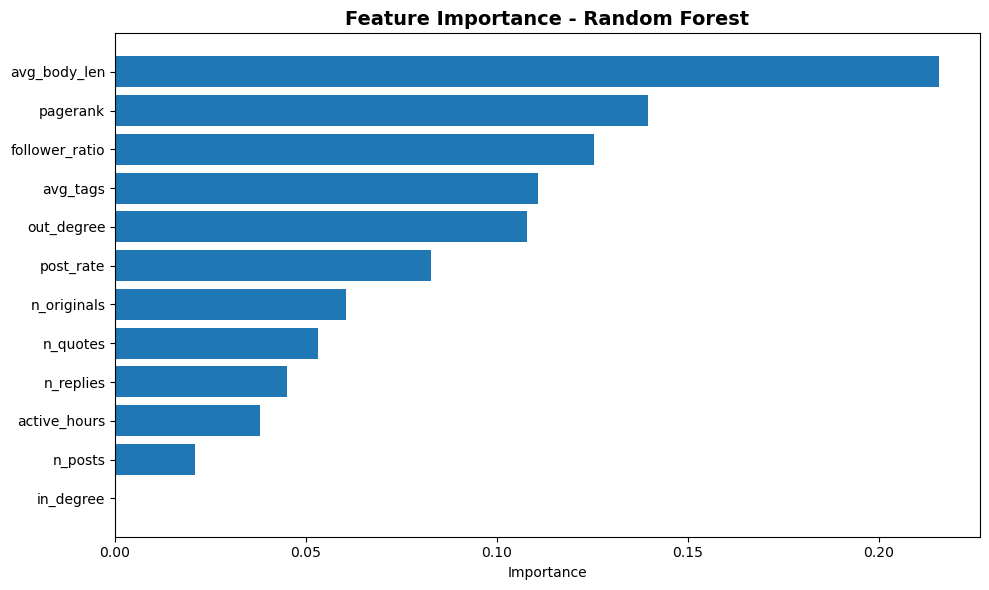

In [ ]:
importances = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

print("=== FEATURE IMPORTANCE ===")
print(importances.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importances["feature"], importances["importance"])
ax.set_xlabel("Importance")
ax.set_title("Feature Importance - Random Forest", fontsize=14, fontweight="bold")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../output/supervised_feature_importance.png", dpi=150, bbox_inches="tight")
print("\n✓ Saved: output/supervised_feature_importance.png")
plt.show()

## 9. Apply to All Accounts

In [ ]:
X_all = accounts[feature_cols].fillna(0).replace([np.inf, -np.inf], np.nan).fillna(0)
X_all_scaled = scaler.transform(X_all)

accounts["predicted_label"] = rf.predict(X_all_scaled)
accounts["predicted_proba"] = rf.predict_proba(X_all_scaled)[:, 1]

comparison = accounts[["username", "buzzer_score", "predicted_proba", "label"]].copy()
comparison = comparison.sort_values("predicted_proba", ascending=False)

print("=== TOP 10 BY  ===")
print(comparison.head(10).to_string(index=False))

corr = accounts[["buzzer_score", "predicted_proba"]].corr().iloc[0, 1]


=== TOP 10 BY  ===
       username  buzzer_score  predicted_proba  label
     aegis00000      0.466391         0.974110    1.0
bukan_fufufafa_      0.549147         0.974110    1.0
      Addaily11      0.539505         0.971347    1.0
         dppPRI      0.395982         0.969561    NaN
 officialinews_      0.425943         0.969561    NaN
    okezonenews      0.425824         0.969561    NaN
     Puspen_TNI      0.381832         0.969561    NaN
   garudatvnews      0.379065         0.969561    NaN
   informasicom      0.421200         0.969561    NaN
     Beritasatu      0.467879         0.969561    1.0


## 10. Comparison: Unsupervised vs Supervised

✓ Saved: output/unsupervised_vs_supervised.png


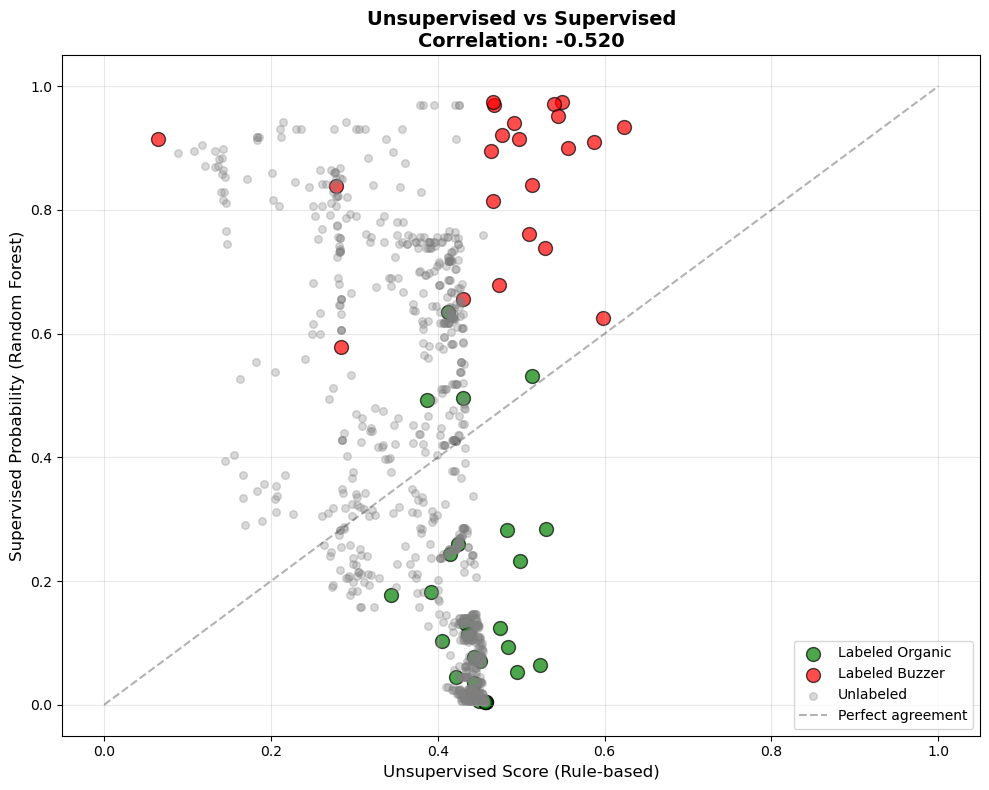

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

labeled_mask = accounts["label"].notna()
buzzer_mask = (accounts["label"] == 1) & labeled_mask
organic_mask = (accounts["label"] == 0) & labeled_mask

ax.scatter(accounts.loc[organic_mask, "buzzer_score"], 
           accounts.loc[organic_mask, "predicted_proba"],
           c="green", label="Labeled Organic", s=100, alpha=0.7, edgecolors="black")
ax.scatter(accounts.loc[buzzer_mask, "buzzer_score"], 
           accounts.loc[buzzer_mask, "predicted_proba"],
           c="red", label="Labeled Buzzer", s=100, alpha=0.7, edgecolors="black")
ax.scatter(accounts.loc[~labeled_mask, "buzzer_score"], 
           accounts.loc[~labeled_mask, "predicted_proba"],
           c="gray", label="Unlabeled", s=30, alpha=0.3)

ax.plot([0, 1], [0, 1], "k--", alpha=0.3, label="Perfect agreement")
ax.set_xlabel("Unsupervised Score (Rule-based)", fontsize=12)
ax.set_ylabel("Supervised Probability (Random Forest)", fontsize=12)
ax.set_title(f"Unsupervised vs Supervised\nCorrelation: {corr:.3f}", 
             fontsize=14, fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../output/unsupervised_vs_supervised.png", dpi=150, bbox_inches="tight")
print("✓ Saved: output/unsupervised_vs_supervised.png")
plt.show()

## 11. Export Results

In [ ]:
import os
os.makedirs("../data/predictions", exist_ok=True)
os.makedirs("../models", exist_ok=True)

predictions = accounts[["account_id", "username", "buzzer_score", 
                       "predicted_label", "predicted_proba", "label"]].copy()
predictions.to_csv("../data/predictions/all_accounts_predictions.csv", index=False)
print("✓ data/predictions/all_accounts_predictions.csv")

import pickle
with open("../models/batch3_rf.pkl", "wb") as f:
    pickle.dump({"model": rf, "scaler": scaler, "features": feature_cols}, f)
print("✓ models/batch3_rf.pkl")


✓ data/predictions/all_accounts_predictions.csv
✓ models/rf_buzzer_detector.pkl
